# 02 · Conversão: CSV (`landing-zone`) → Delta Lake (`bronze`)

Lê os CSVs do bucket `landing-zone` com o Spark e grava cada tabela no formato **Delta Lake** no bucket `bronze`.

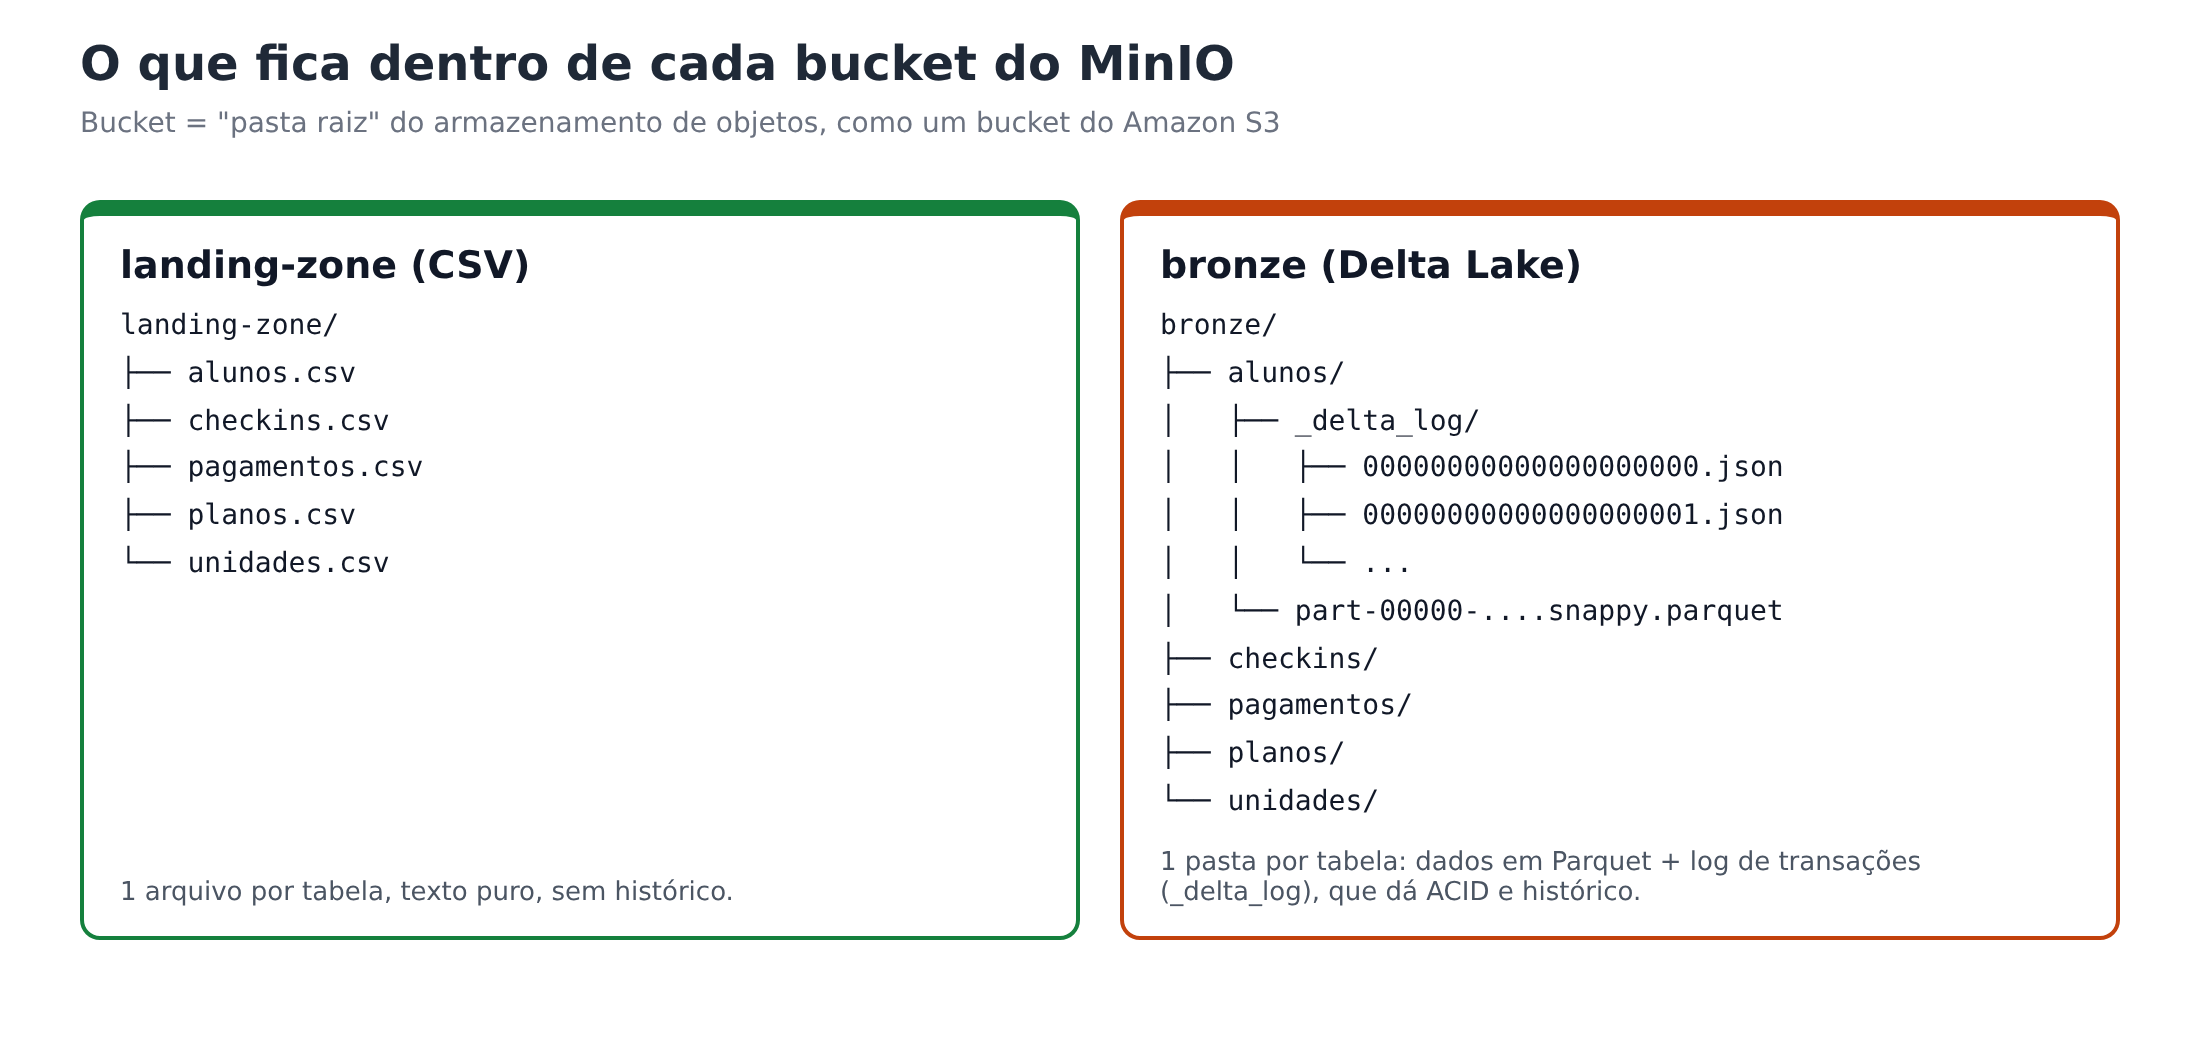

**Antes de rodar:** notebook `01` executado. O SQL Server não é mais usado a partir daqui
(se o computador estiver com pouca memória, dá para pará-lo com `docker stop sqlserver-2025`).

## 1. Configuração e SparkSession

> **Primeira execução:** o Spark baixa da internet os pacotes `.jar` do Delta Lake e do conector S3A
> (incluindo o SDK da AWS, com cerca de 280 MB). Pode levar alguns minutos. Depois disso fica em cache em `~/.ivy2`.

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Raiz do projeto (funciona abrindo o notebook pelo VS Code, pelo JupyterLab ou pelo nbconvert)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / ".env").exists():
    raise FileNotFoundError("Arquivo .env não encontrado. Na raiz do projeto rode: cp .env.example .env")
load_dotenv(ROOT / ".env", override=True)

MINIO_ENDPOINT   = os.getenv("MINIO_ENDPOINT")
MINIO_ACCESS_KEY = os.getenv("MINIO_ACCESS_KEY")
MINIO_SECRET_KEY = os.getenv("MINIO_SECRET_KEY")
LANDING_BUCKET   = os.getenv("MINIO_LANDING_BUCKET")
BRONZE_BUCKET    = os.getenv("MINIO_BRONZE_BUCKET")

print(f"MinIO: {MINIO_ENDPOINT} | {LANDING_BUCKET} -> {BRONZE_BUCKET}")

In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("CSV_para_Delta")
    .master("local[*]")
    # Delta Lake + conector S3A (para o Spark ler e gravar no MinIO como se fosse o Amazon S3)
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.2.0,org.apache.hadoop:hadoop-aws:3.3.4")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.warehouse.dir", str(ROOT / "spark-warehouse"))
    .config("spark.driver.memory", "2g")
    # MinIO via S3A
    .config("spark.hadoop.fs.s3a.endpoint", MINIO_ENDPOINT)
    .config("spark.hadoop.fs.s3a.access.key", MINIO_ACCESS_KEY)
    .config("spark.hadoop.fs.s3a.secret.key", MINIO_SECRET_KEY)
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

## 2. Criar o bucket `bronze`

In [ ]:
import boto3
from botocore.client import Config

s3 = boto3.client(
    "s3",
    endpoint_url=MINIO_ENDPOINT,
    aws_access_key_id=MINIO_ACCESS_KEY,
    aws_secret_access_key=MINIO_SECRET_KEY,
    config=Config(signature_version="s3v4"),
    region_name="us-east-1",
)


def garantir_bucket(nome):
    """Cria o bucket no MinIO se ele ainda não existir."""
    existentes = [b["Name"] for b in s3.list_buckets()["Buckets"]]
    if nome in existentes:
        print(f"Bucket [{nome}] já existe")
    else:
        s3.create_bucket(Bucket=nome)
        print(f"Bucket [{nome}] criado!")

garantir_bucket(BRONZE_BUCKET)

## 3. Esquema de cada tabela

Em vez de deixar o Spark "adivinhar" os tipos (`inferSchema`), declaramos o esquema de cada tabela.
Assim os tipos ficam iguais aos do SQL Server (`DECIMAL(10,2)` continua decimal, `DATE` continua data)
e, com `mode = FAILFAST`, a leitura **falha** se alguma linha do CSV vier fora do formato, em vez de virar nulo em silêncio.

In [ ]:
SCHEMAS = {
    "unidades":   "id_unidade INT, nome STRING, cidade STRING, bairro STRING, data_inauguracao DATE",
    "planos":     "id_plano INT, nome STRING, valor_mensal DECIMAL(10,2), duracao_meses INT",
    "alunos":     "id_aluno INT, nome STRING, email STRING, cidade STRING, id_plano INT, data_matricula DATE, ativo BOOLEAN",
    "checkins":   "id_checkin INT, id_aluno INT, id_unidade INT, data_hora TIMESTAMP",
    "pagamentos": "id_pagamento INT, id_aluno INT, competencia DATE, data_pagamento DATE, valor DECIMAL(10,2), "
                  "forma_pagamento STRING, status STRING",
}

arquivos = sorted(o["Key"] for o in s3.list_objects_v2(Bucket=LANDING_BUCKET).get("Contents", [])
                  if o["Key"].endswith(".csv"))
print("CSVs na landing-zone:", arquivos)
faltando = set(SCHEMAS) - {a.removesuffix(".csv") for a in arquivos}
assert not faltando, f"Faltam CSVs na landing-zone: {faltando}. Rode o notebook 01."

## 4. Ler os CSVs e gravar em Delta Lake

`mode("overwrite")` substitui o conteúdo da tabela, mas **não apaga o histórico**: cada execução vira uma nova versão.
Por isso dá para rodar este notebook de novo sempre que quiser "recarregar" o bronze.

In [ ]:
contagens = {}
for tabela, schema in SCHEMAS.items():
    origem = f"s3a://{LANDING_BUCKET}/{tabela}.csv"
    destino = f"s3a://{BRONZE_BUCKET}/{tabela}"

    df = (spark.read
          .option("header", "true")
          .option("encoding", "UTF-8")
          .option("mode", "FAILFAST")
          .schema(schema)
          .csv(origem))

    (df.write
       .format("delta")
       .mode("overwrite")
       .option("overwriteSchema", "true")
       .save(destino))

    contagens[tabela] = df.count()
    print(f"  {tabela:<11} {contagens[tabela]:>6} registros  {origem}  ->  {destino}")

## 5. Validação

In [ ]:
from delta.tables import DeltaTable

for tabela in SCHEMAS:
    caminho = f"s3a://{BRONZE_BUCKET}/{tabela}"
    eh_delta = DeltaTable.isDeltaTable(spark, caminho)
    total = spark.read.format("delta").load(caminho).count()
    print(f"  {tabela:<11} Delta={eh_delta}  registros={total}")
    assert eh_delta and total == contagens[tabela], f"Problema na tabela {tabela}"
print("\nOK: as 5 tabelas estão no bucket bronze em formato Delta.")

In [ ]:
# Tipos preservados (compare com o DDL do SQL Server no notebook 00)
spark.read.format("delta").load(f"s3a://{BRONZE_BUCKET}/pagamentos").printSchema()
spark.read.format("delta").load(f"s3a://{BRONZE_BUCKET}/unidades").show()

In [ ]:
# Como a tabela ficou no MinIO: arquivos Parquet + pasta _delta_log
for o in s3.list_objects_v2(Bucket=BRONZE_BUCKET, Prefix="planos/").get("Contents", []):
    print(f"  {o['Key']:<75} {o['Size']:>7} bytes")

In [ ]:
spark.stop()
print("SparkSession encerrada.")